# Assignment 1 Code:
### Alison Attard 2929661

In [331]:
# imports
import math
import random
import matplotlib.pyplot as plt
import numpy as np

## Part 2: Scalar Backpropagation
### Question 3:

### Softmax function

In [332]:
# computing softmax of a vector x
def softmax(x):
    # calculating soft max
    exps = []
    for i in x:
        exps.append(math.exp(i))
    summation = sum(exps)
    # normalizing the values
    for i in range(len(exps)):
        exps[i]= exps[i]/summation
    return exps 

### Cross-Entropy Loss function

In [333]:
# computing loss 
def cross_entropy(target, y_pred):
    # probability at true class
    p = y_pred[target]
    # avoid log(0) error:
    eps = 1e-15
    # clip values to avoid having. a 0 in the log 
    p = min(max(p, eps), 1-eps)
    # returning cross entropy loss
    return -math.log(p)

### Sigmoid Activation function

In [334]:
# sigmoid activation function
def sigmoid(x):
    return 1/(1 + math.exp(-x))

In [335]:
# inputs
x = [1.000, -1.000]
# weights 
w = [[1, 1, 1], [-1, -1, -1]]
# bias
b = [0, 0, 0]
# second layer weights
v = [[1,1], [-1, -1], [-1, -1]]
# second layer bias
bias2 = [0, 0]

# hidden nodes
k = [0., 0., 0.]
h = [0., 0., 0.]
# output nodes
o = [0., 0.]

# forward pass

# first linear layer
# linear output k and sigmoid activation h
for j in range(len(k)):
    #weighted sum of inputs
    for i in range(len(x)):
        k[j] += x[i]*w[i][j]
    # add bias 
    k[j] += b[j]
    h[j] = sigmoid(k[j])
    

# second linear layer
for j in range(len(o)):
    for i in range(len(h)):
        o[j] += h[i]*v[i][j]
    o[j] += bias2[j]

# softmax probability
y = softmax(o)

target = 0
# computing loss function
loss = cross_entropy(target, y)
print("loss: ", loss)

# printing to check
print("h: ", h)
print("k: ", k)
print("o: ", o)

# backwards pass

# gradients initialised to 0
dw = [[0, 0, 0], [0, 0, 0]]
db = [0, 0, 0]
dv = [[0, 0], [0, 0], [0, 0]]
dbias2 = [0, 0]
dl_do = [0, 0]
dl_dh = [0, 0, 0]
dl_dk = [0, 0, 0]

# loss and softmax
for i in range(len(dl_do)):
    dl_do[i] = y[i] - (1 if i == target else 0)

# second layer
for i in range(len(dbias2)):
    dbias2[i] = dl_do[i] * 1

for i in range(len(h)):
    for j in range(len(dl_do)):
        dv[i][j] = dl_do[j] * h[i]

# gradient flowing back to hidden layer summed
for i in range(len(dl_dh)):
    for j in range(len(dl_do)):
        dl_dh[i] += dl_do[j] * v[i][j]

#through sigmoid
for i in range(len(dl_dk)):
    dl_dk[i] = dl_dh[i] * h[i] * (1 - h[i])

# first layer bias & weight
for i in range(len(db)):
    db[i] = dl_dk[i] * 1

# dw
for i in range(len(dw)):
    for j in range(len(dw[0])):
        dw[i][j] = dl_dk[j] * x[i]


loss:  0.6931471805599453
h:  [0.8807970779778823, 0.8807970779778823, 0.8807970779778823]
k:  [2.0, 2.0, 2.0]
o:  [-0.8807970779778823, -0.8807970779778823]


### 

In [336]:
def clean(a, d=4):
    # round, and turn -0.0 into 0.0
    if isinstance(a, list):
        return [clean(t, d) for t in a]
    return round(a, d) + 0.0

print("forward pass")
print("k:", clean(k))
print("h:", clean(h))
print("o:", clean(o))
print("y:", clean(y))
print("loss:", clean(loss))

print("\nbackward pass")
print("dl_do:", clean(dl_do))
print("dl_dh:", clean(dl_dh))
print("dl_dk:", clean(dl_dk))

print("\nderivatives wrt W, b:")
print(clean(dw), clean(db))
print("derivatives wrt V, c:")
print(clean(dv), clean(dbias2))

forward pass
k: [2.0, 2.0, 2.0]
h: [0.8808, 0.8808, 0.8808]
o: [-0.8808, -0.8808]
y: [0.5, 0.5]
loss: 0.6931

backward pass
dl_do: [-0.5, 0.5]
dl_dh: [0.0, 0.0, 0.0]
dl_dk: [0.0, 0.0, 0.0]

derivatives wrt W, b:
[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0]] [0.0, 0.0, 0.0]
derivatives wrt V, c:
[[-0.4404, 0.4404], [-0.4404, 0.4404], [-0.4404, 0.4404]] [-0.5, 0.5]


### Question 4:

#### Training on a dataset

In [337]:
# loading from data.py file
from data import load_synth, load_mnist

# loading data
(x_train, y_train), (xval, yval), num_cls = load_synth()

# print shape
print("shape of x_train: ", x_train.shape)
print("shape of y_train: ", y_train.shape)
print("shape of xval: ", xval.shape)
print("shape of yval: ", yval.shape)
print("number of classes: ", num_cls)

# min max mean xtrain
print("min of x_train: ", x_train.min())
print("max of x_train: ", x_train.max())
print("mean of x_train: ", x_train.mean())

# head of x_train
print("head of x_train:\n", x_train[:5])

shape of x_train:  (60000, 2)
shape of y_train:  (60000,)
shape of xval:  (10000, 2)
shape of yval:  (10000,)
number of classes:  2
min of x_train:  -4.852117653180117
max of x_train:  4.285855641221728
mean of x_train:  0.0029853645282486106
head of x_train:
 [[ 1.76405235  0.40015721]
 [ 0.97873798  2.2408932 ]
 [ 1.86755799 -0.97727788]
 [ 0.95008842 -0.15135721]
 [-0.10321885  0.4105985 ]]


In [338]:
def forward_pass(x, w, b, v, bias2):
    n_hidden = len(b)
    n_out = len(bias2)

    k = [0.] * n_hidden
    h = [0.] * n_hidden
    o = [0.] * n_out

    # first linear layer
    for j in range(n_hidden):
        for i in range(len(x)):
            k[j] += x[i] * w[i][j]
        k[j] += b[j]
        h[j] = sigmoid(k[j])

    # second linear layer
    for j in range(n_out):
        for i in range(n_hidden):
            o[j] += h[i] * v[i][j]
        o[j] += bias2[j]

    y = softmax(o)
    return k, h, o, y

k, h, o, y = forward_pass(x, w, b, v, bias2)


In [339]:
# backward pass
def backward_pass(x, h, y, target, w, b, v, bias2):
    n_hidden = len(b)
    n_out = len(bias2)

    # gradients initialised to 0
    dw = [[0] * n_hidden for _ in range(len(x))]
    db = [0] * n_hidden
    dv = [[0] * n_out for _ in range(n_hidden)]
    dbias2 = [0] * n_out
    dl_do = [0] * n_out
    dl_dh = [0] * n_hidden
    dl_dk = [0] * n_hidden

    # loss and softmax
    for i in range(n_out):
        dl_do[i] = y[i] - (1 if i == target else 0)

    # second layer
    for i in range(n_out):
        dbias2[i] = dl_do[i]

    for i in range(n_hidden):
        for j in range(n_out):
            dv[i][j] = dl_do[j] * h[i]

    # gradient flowing back to hidden layer summed
    for i in range(n_hidden):
        for j in range(n_out):
            dl_dh[i] += dl_do[j] * v[i][j]

    # through sigmoid
    for i in range(n_hidden):
        dl_dk[i] = dl_dh[i] * h[i] * (1 - h[i])

    # first layer bias & weight
    for i in range(n_hidden):
        db[i] = dl_dk[i]

    # dw
    for i in range(len(x)):
        for j in range(n_hidden):
            dw[i][j] = dl_dk[j] * x[i]

    return dw, db, dv, dbias2, dl_do, dl_dh, dl_dk

In [340]:
# printing to check
print(k, h, o, y)

k, hh, o, yy = forward_pass(x, w, b, v, bias2)
dw, db, dv, dbias2, dl_do, dl_dh, dl_dk = backward_pass(x, hh, yy, 0, w, b, v, bias2)
print(dw, db, dv, dbias2)

[2.0, 2.0, 2.0] [0.8807970779778823, 0.8807970779778823, 0.8807970779778823] [-0.8807970779778823, -0.8807970779778823] [0.5, 0.5]
[[0.0, 0.0, 0.0], [-0.0, -0.0, -0.0]] [0.0, 0.0, 0.0] [[-0.44039853898894116, 0.44039853898894116], [-0.44039853898894116, 0.44039853898894116], [-0.44039853898894116, 0.44039853898894116]] [-0.5, 0.5]


In [341]:
# initialising parameters
def init_params(n_in, n_hidden, n_out):
    w = [[random.gauss(0, 1) for _ in range(n_hidden)] for _ in range(n_in)]
    v = [[random.gauss(0, 1) for _ in range(n_out)] for _ in range(n_hidden)]
    b = [0.] * n_hidden
    bias2 = [0.] * n_out
    return w, b, v, bias2


In [342]:
# training loop
# settings
lr = 0.01
epochs = 1000
n_hidden = 3
n_train = 1000
xs = x_train[:n_train].tolist()
ys = [int(t) for t in y_train[:n_train]]

# fresh parameters every run
random.seed(83)
w_t, b_t, v_t, bias2_t = init_params(len(xs[0]), n_hidden, num_cls)

losses = []
for epoch in range(epochs):
    total = 0.
    for x_i, t_i in zip(xs, ys):
        _, h, _, y = forward_pass(x_i, w_t, b_t, v_t, bias2_t)
        total += cross_entropy(t_i, y)
        dw, db, dv, dbias2, *_ = backward_pass(x_i, h, y, t_i, w_t, b_t, v_t, bias2_t)
        
        for i in range(len(w_t)):
            for j in range(len(w_t[0])):
                w_t[i][j] -= lr * dw[i][j]
        for i in range(len(v_t)):
            for j in range(len(v_t[0])):
                v_t[i][j] -= lr * dv[i][j]
        for j in range(len(b_t)):
            b_t[j] -= lr * db[j]
        for j in range(len(bias2_t)):
            bias2_t[j] -= lr * dbias2[j]

    losses.append(total / len(xs))
    print("Epoch %d, loss: %.4f" % (epoch, total / len(xs)))

Epoch 0, loss: 0.6874
Epoch 1, loss: 0.6861
Epoch 2, loss: 0.6848
Epoch 3, loss: 0.6833
Epoch 4, loss: 0.6812
Epoch 5, loss: 0.6781
Epoch 6, loss: 0.6736
Epoch 7, loss: 0.6668
Epoch 8, loss: 0.6561
Epoch 9, loss: 0.6392
Epoch 10, loss: 0.6135
Epoch 11, loss: 0.5767
Epoch 12, loss: 0.5299
Epoch 13, loss: 0.4781
Epoch 14, loss: 0.4282
Epoch 15, loss: 0.3844
Epoch 16, loss: 0.3478
Epoch 17, loss: 0.3178
Epoch 18, loss: 0.2934
Epoch 19, loss: 0.2734
Epoch 20, loss: 0.2569
Epoch 21, loss: 0.2431
Epoch 22, loss: 0.2314
Epoch 23, loss: 0.2213
Epoch 24, loss: 0.2125
Epoch 25, loss: 0.2048
Epoch 26, loss: 0.1980
Epoch 27, loss: 0.1918
Epoch 28, loss: 0.1863
Epoch 29, loss: 0.1812
Epoch 30, loss: 0.1766
Epoch 31, loss: 0.1724
Epoch 32, loss: 0.1686
Epoch 33, loss: 0.1650
Epoch 34, loss: 0.1617
Epoch 35, loss: 0.1586
Epoch 36, loss: 0.1558
Epoch 37, loss: 0.1531
Epoch 38, loss: 0.1506
Epoch 39, loss: 0.1483
Epoch 40, loss: 0.1462
Epoch 41, loss: 0.1441
Epoch 42, loss: 0.1422
Epoch 43, loss: 0.140

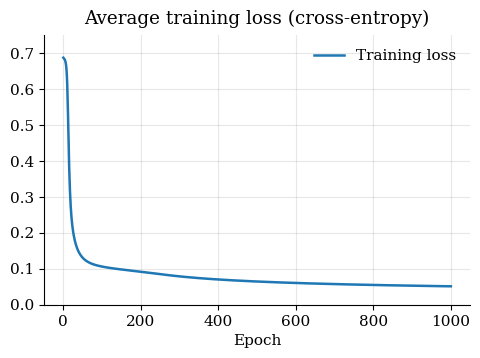

In [343]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(range(1, len(losses) + 1), losses, linewidth=1.8, label="Training loss")

ax.set_xlabel("Epoch")
ax.set_title("Average training loss (cross-entropy)", loc="center", pad=8)
ax.set_ylim(0, 0.75)

ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
fig.savefig("q4_loss.pdf", bbox_inches="tight")
plt.show()

## Part3: Tensor Backpropogation

### Question 5:

In [344]:
# loading dataset
(xtrain, ytrain), (xval, yval), num_cls = load_mnist(final=False)

print("shape of x_train: ", xtrain.shape)
print("shape of x_val: ", xval.shape)
print("min of x_train: ", xtrain.min())
print("max of x_train: ", xtrain.max())

# training statistics, reused for the validation set
mu = xtrain.mean()
sigma = xtrain.std() + 1e-8

# normalising data
xtrain = (xtrain - mu) / sigma
xval = (xval - mu) / sigma

print("After normalising:")
print("train mean, std: ", xtrain.mean().round(4), xtrain.std().round(4))
print("val mean, std: ", xval.mean().round(4), xval.std().round(4))
print("train min, max: ", xtrain.min(), xtrain.max())

shape of x_train:  (55000, 784)
shape of x_val:  (5000, 784)
min of x_train:  0
max of x_train:  255
After normalising:
train mean, std:  0.0 1.0
val mean, std:  -0.0005 0.9996
train min, max:  -0.4241007948015875 2.82141045189666


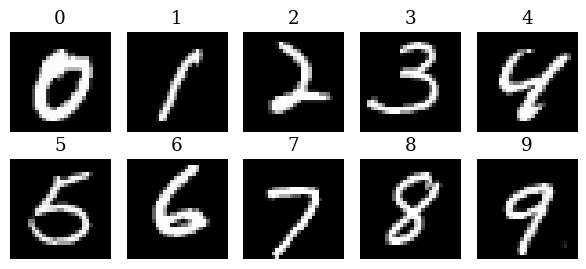

In [370]:
fig, axes = plt.subplots(2, 5, figsize=(6, 2.8))
for d, ax in enumerate(axes.flat):
    idx = int(np.where(ytrain == d)[0][0])
    ax.imshow(xtrain[idx].reshape(28, 28), cmap="gray")
    ax.set_title(str(d))
    ax.axis("off")
fig.tight_layout()
fig.savefig("mnist_samples.pdf", bbox_inches="tight")
plt.show()

In [345]:
# initialising parameters
def init_params(n_in, n_hidden, n_out, seed=83):
    rng = np.random.default_rng(seed)
    W = rng.normal(0, 1 / np.sqrt(n_in), size=(n_in, n_hidden))
    # n_hidden for both the scaling and the first dimension
    V = rng.normal(0, 1 / np.sqrt(n_hidden), size=(n_hidden, n_out))
    # zeros of length n_hidden
    b = np.zeros(n_hidden)
    # zeros of length n_out
    c = np.zeros(n_out)
    return W, b, V, c

# sigmoid
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# softmax
def softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

# forward pass
def forward(x, W, b, V, c):
    # first linear layer
    k = np.dot(x, W) + b
    h = sigmoid(k)

    # second linear layer
    o = np.dot(h, V) + c

    # softmax probability
    y = softmax(o)
    return k, h, o, y

In [346]:
# testing
W, b, V, c = init_params(784, 300, 10)
k, h, o, y = forward(xtrain[0], W, b, V, c)
print(k.shape, h.shape, o.shape, y.shape)
print(y.sum(), cross_entropy(ytrain[0], y))


(300,) (300,) (10,) (10,)
1.0 3.0095588127845505


### Question 6:

In [354]:
# backward pass
def backward(x, h, y, target, W, b, V, c):
    # loss and softmax
    dl_do = y.copy()
    dl_do[target] -= 1

    # second layer
    dbias2 = dl_do.copy()
    dv = np.outer(h, dl_do)

    # gradient flowing back to hidden layer summed
    dl_dh = np.dot(V, dl_do)

    # through sigmoid
    dl_dk = dl_dh * h * (1 - h)

    # first layer bias & weight
    db = dl_dk.copy()
    dw = np.outer(x, dl_dk)

    return dw, db, dv, dbias2, dl_do, dl_dh, dl_dk

In [358]:
# training loop
# settings
lr = 0.01
epochs = 3
n_train = len(xtrain)

# fresh parameters every run
W, b, V, c = init_params(784, 300, 10)
rng = np.random.default_rng(83)

losses = []
for epoch in range(epochs):
    # random order of the training images
    order = rng.permutation(n_train)
    for i in order:
        x_i = xtrain[i]
        t_i = int(ytrain[i])

        # forward pass
        k, h, o, y = forward(x_i, W, b, V, c)
        # compute the loss and append it to losses
        loss = cross_entropy(t_i, y)
        losses.append(loss)
        # backward pass
        dw, db, dv, dbias2, *_ = backward(x_i, h, y, t_i, W, b, V, c)
        # update W, b, V, c
        W -= lr * dw
        b -= lr * db
        V -= lr * dv
        c -= lr * dbias2

# checking loss drop
print("first 500:", np.mean(losses[:500]))
print("last 500:", np.mean(losses[-500:]))

first 500: 1.5036537984709986
last 500: 0.06899837152655508


[np.float64(0.26130542138271057), np.float64(0.11008809083413346), np.float64(0.07071569788977951)]


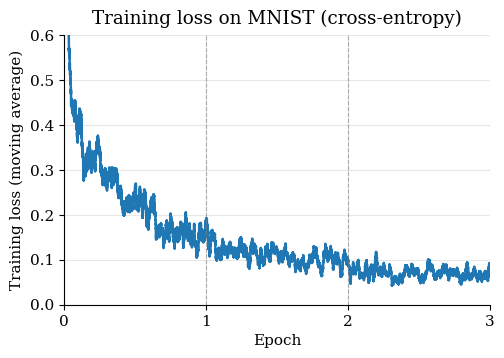

In [367]:
per_epoch = len(xtrain)
print([np.mean(losses[e*per_epoch:(e+1)*per_epoch]) for e in range(3)])

# plotting mean loss per epoch moving avg over 1000
window = 1000
per_epoch = len(xtrain)

smooth = np.convolve(losses, np.ones(window) / window, mode='valid')
steps = np.arange(window, len(losses) + 1) / per_epoch

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(steps, smooth, linewidth=1.8, color="#1f77b4")

for e in range(1, epochs):
    ax.axvline(e, color="grey", linestyle="--", linewidth=0.8, alpha=0.6)

ax.set_xlabel("Epoch")
ax.set_ylabel("Training loss (moving average)")
ax.set_title("Training loss on MNIST (cross-entropy)", loc="center", pad=8)
ax.set_xlim(0, epochs)
ax.set_ylim(0, 0.6)
ax.set_xticks(range(epochs + 1))
ax.grid(True, alpha=0.3)
fig.savefig("q6_loss.pdf", bbox_inches="tight")
plt.show()

### Question 7*

In [ ]:
# doing this on batches

# forward pass

# row wise softmax
def softmax_batch(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

def forward_batch(X, W, b, V, c):
    k = X @ W + b
    h = sigmoid(k)
    o = h @ V + c
    y = softmax_batch(o)

    return k, h, o, y

# backward pass
def backward_batch(X, h, y, targets, W, b, V, c):
    n_samples = X.shape[0]
    dl_do = y.copy()
    dl_do[np.arange(n_samples), targets] -= 1
    dl_do /= n_samples

    # second layer
    dbias2 = np.sum(dl_do, axis=0)
    dv = h.T @ dl_do

    dl_dh = dl_do @ V.T
    dl_dk = dl_dh * h * (1 - h)

    db = np.sum(dl_dk, axis=0)
    dw = X.T @ dl_dk

    return dw, db, dv, dbias2, dl_do, dl_dh, dl_dk

# cross entropy
def cross_entropy_batch(y_true, y_pred):
    n_samples = y_true.shape[0]
    # probability at true class
    p = y_pred[np.arange(n_samples), y_true]
    # avoid log(0) error:
    eps = 1e-15
    # clip values to avoid having a 0 in the log 
    p = np.clip(p, eps, 1 - eps)
    # returning cross entropy loss
    return -np.mean(np.log(p))


2.7754794104587126 2.7754794104587126


In [389]:
# training loop

# settings
lr = 0.01
epochs = 3
batch_size = 100
n_train = len(xtrain)

# fresh parameters
W, b, V, c = init_params(784, 300, 10)
rng = np.random.default_rng(83)

batch_losses = []
for epoch in range(epochs):
    # random order of the training images
    order = rng.permutation(n_train)
    for start in range(0, n_train, batch_size):
        idx = order[start:start + batch_size]
        X_b = xtrain[idx]
        t_b = ytrain[idx].astype(int)

        # forward pass, keep h and y
        k, h, o, y = forward_batch(X_b, W, b, V, c)

        # batch loss, append to batch_losses
        loss = cross_entropy_batch(t_b, y)
        batch_losses.append(loss)

        # backward pass, keep the four gradients
        dw, db, dv, dbias2, *_ = backward_batch(X_b, h, y, t_b, W, b, V, c)

        # update W, b, V, c
        W -= lr * dw
        b -= lr * db
        V -= lr * dv
        c -= lr * dbias2

        

/var/folders/0c/hjszxlb13jb8vnn82fy3y__40000gn/T/ipykernel_1290/4074201750.py:11: RuntimeWarning: divide by zero encountered in matmul
  k = X @ W + b
/var/folders/0c/hjszxlb13jb8vnn82fy3y__40000gn/T/ipykernel_1290/4074201750.py:11: RuntimeWarning: overflow encountered in matmul
  k = X @ W + b
/var/folders/0c/hjszxlb13jb8vnn82fy3y__40000gn/T/ipykernel_1290/4074201750.py:11: RuntimeWarning: invalid value encountered in matmul
  k = X @ W + b
/var/folders/0c/hjszxlb13jb8vnn82fy3y__40000gn/T/ipykernel_1290/4074201750.py:13: RuntimeWarning: divide by zero encountered in matmul
  o = h @ V + c
/var/folders/0c/hjszxlb13jb8vnn82fy3y__40000gn/T/ipykernel_1290/4074201750.py:13: RuntimeWarning: overflow encountered in matmul
  o = h @ V + c
/var/folders/0c/hjszxlb13jb8vnn82fy3y__40000gn/T/ipykernel_1290/4074201750.py:13: RuntimeWarning: invalid value encountered in matmul
  o = h @ V + c
/var/folders/0c/hjszxlb13jb8vnn82fy3y__40000gn/T/ipykernel_1290/4074201750.py:27: RuntimeWarning: divide by 

In [390]:
print("first 50 batches:", np.mean(batch_losses[:50]))
print("last 50 batches:", np.mean(batch_losses[-50:]))

first 50 batches: 2.1694147566233095
last 50 batches: 0.4772107100109508


## Part 4: Analysis

### Question 8:

In [349]:
# 1. traoning loss vs validation loss

In [350]:
# 2. avg and std of random initialisations

In [351]:
# 3. diff learning rates

In [352]:
# 4. final set of hyperparameters & report accuracy

### additional resources used:

#### q1: 
- https://eli.thegreenplace.net/2016/the-softmax-function-and-its-derivative/
- https://www.datacamp.com/tutorial/the-cross-entropy-loss-function-in-machine-learning


#### q3: